# Bivariate Spatial Cross-Correlation (Moran's I)

**Aim 2 — Spatial co-localization of cell types across metastasis groups**

For each sample, computes bivariate Moran's I between Cell2Location abundance scores for key cell type pairs. Tests whether spatial co-localization differs by metastasis group.

This provides quantitative evidence for spatial co-localization that motivates the NMF niche analysis.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import os
import warnings
from scipy.spatial import KDTree
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION
# ============================================================
SAMPLE_DIR = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"
META_PATH = "/Users/adiallo/Desktop/Thesis/Data_Documents/data_all.csv"
OUTPUT_DIR = "/Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation"
ABUNDANCE_KEY = "means_cell_abundance_w_sf"

os.makedirs(OUTPUT_DIR, exist_ok=True)

## Cell Type Pairs and Mappings

Biologically motivated pairs testing immune infiltration, exclusion, and immunosuppressive niche formation.

In [2]:
# Cell type pairs to test
CELL_TYPE_PAIRS = [
    ("Tumor", "CD8"),
    ("Tumor", "Treg"),
    ("Tumor", "Macrophage"),
    ("Tumor", "CAF"),
    ("CAF", "CD8"),
    ("CAF", "Treg"),
    ("CAF", "Macrophage"),
    ("Tumor", "DC"),
]

# Mapping from broad names to Cell2Location column patterns
BROAD_TO_C2L = {
    "Tumor":      ["Tumor"],
    "CD8":        ["cTNI10", "cTNI11", "cTNI12", "cTNI13", "cTNI14", "cTNI15", "cTNI16"],
    "CD4":        ["cTNI01", "cTNI02", "cTNI03", "cTNI04", "cTNI05", "cTNI06", "cTNI07"],
    "Treg":       ["cTNI08", "cTNI09"],
    "CAF":        ["cS27", "cS28", "cS29", "cS30", "cS31"],
    "Macrophage": ["cM01", "cM02"],
    "DC":         ["cM03", "cM04", "cM05", "cM06", "cM07", "cM08", "cM09"],
    "NK":         ["cTNI23", "cTNI24", "cTNI25"],
    "B_cell":     ["cB1", "cB2", "cB3"],
    "Fibroblast": ["cS21", "cS22", "cS23", "cS24", "cS25"],
}

## Helper Functions

Abundance scoring, spatial weight matrix construction, bivariate Moran's I, and permutation testing.

In [9]:
def get_abundance_score(adata, broad_type):
    """Sum Cell2Location abundances for columns matching a broad cell type."""
    abund = adata.obsm[ABUNDANCE_KEY]
    patterns = BROAD_TO_C2L.get(broad_type, [])
    
    matching_cols = []
    for col in abund.columns:
        for pattern in patterns:
            clean = col.replace("meanscell_abundance_w_sf_", "").replace("means_cell_abundance_w_sf_", "")
            if clean.startswith(pattern) or pattern in clean:
                matching_cols.append(col)
                break
    
    if len(matching_cols) == 0:
        return None
    
    return abund[matching_cols].sum(axis=1).values


def spatial_weights_knn(coords, k=6):
    """Build row-normalized spatial weight matrix using k nearest neighbors."""
    tree = KDTree(coords)
    dists, indices = tree.query(coords, k=k+1)  # +1 for self
    
    n = len(coords)
    W = np.zeros((n, n))
    for i in range(n):
        neighbors = indices[i, 1:]  # skip self
        W[i, neighbors] = 1.0
    
    # Row-normalize
    row_sums = W.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    W = W / row_sums
    
    return W


def bivariate_morans_i(x, y, W):
    """
    Compute bivariate Moran's I between variables x and y.
    Measures correlation between x and the spatial lag of y.
    """
    n = len(x)
    
    # Standardize
    zx = (x - x.mean()) / (x.std() + 1e-10)
    zy = (y - y.mean()) / (y.std() + 1e-10)
    
    # Spatial lag of y
    Wy = W @ zy
    
    # Bivariate Moran's I = correlation of x with spatial lag of y
    I = np.sum(zx * Wy) / n
    
    return I


def permutation_test(x, y, W, n_perms=9999):
    """Permutation test for bivariate Moran's I."""
    observed = bivariate_morans_i(x, y, W)
    
    count = 0
    for _ in range(n_perms):
        y_perm = np.random.permutation(y)
        I_perm = bivariate_morans_i(x, y_perm, W)
        if abs(I_perm) >= abs(observed):
            count += 1
    
    p_value = (count + 1) / (n_perms + 1)
    return observed, p_value

## Load Clinical Metadata

In [10]:
print("=" * 70)
print("BIVARIATE SPATIAL CROSS-CORRELATION ANALYSIS")
print("=" * 70)

clinical = pd.read_csv(META_PATH)
clinical.columns = clinical.columns.str.strip()
clinical["deident"] = clinical["deident"].astype(str)

# ----------------------------------------------------------------
# Metastasis group assignment
# NOTE: ln_only and any_mets are encoded as "T"/"F" strings,
#       Distant_Mets is boolean.  Normalise everything to uppercase
#       strings before comparison to avoid silent misclassification.
# ----------------------------------------------------------------
def get_mets_group(row):
    """Three-level stratification: No_Mets / LN_Mets / Distant_Mets."""
    dm = str(row.get("Distant_Mets", "")).strip().upper()
    ln = str(row.get("ln_only", "")).strip().upper()
    
    if dm in ["T", "TRUE", "1", "YES"]:
        return "Distant_Mets"
    elif ln in ["T", "TRUE", "1", "YES"]:
        return "LN_Mets"
    else:
        return "No_Mets"

def get_mets_binary(row):
    """Two-level stratification matching Table 1: Any_Mets vs No_Mets."""
    am = str(row.get("any_mets", "")).strip().upper()
    if am in ["T", "TRUE", "1", "YES"]:
        return "Any_Mets"
    else:
        return "No_Mets"

clinical["mets_group"] = clinical.apply(get_mets_group, axis=1)
clinical["mets_binary"] = clinical.apply(get_mets_binary, axis=1)

# ---- Verify on Visium subset ----
h5ad_files = [f for f in os.listdir(SAMPLE_DIR) if f.endswith(".h5ad")]
h5ad_files = [f for f in h5ad_files if f.replace('.h5ad', '').isdigit()]
visium_ids = [f.replace('.h5ad', '') for f in h5ad_files]

visium_clinical = clinical[clinical["deident"].isin(visium_ids)]

print("\nThree-group stratification (Visium samples):")
print(visium_clinical["mets_group"].value_counts())
print("\nTwo-group stratification (Visium samples, matches Table 1):")
print(visium_clinical["mets_binary"].value_counts())

assert len(visium_ids) == 41, f"Expected 41 Visium samples, got {len(visium_ids)}"

BIVARIATE SPATIAL CROSS-CORRELATION ANALYSIS

Three-group stratification (Visium samples):
mets_group
No_Mets         19
LN_Mets         12
Distant_Mets    10
Name: count, dtype: int64

Two-group stratification (Visium samples, matches Table 1):
mets_binary
Any_Mets    22
No_Mets     19
Name: count, dtype: int64


## Compute Bivariate Moran's I Per Sample

For each sample and cell type pair, compute bivariate Moran's I with permutation test (999 permutations).

**Note:** This may take 30-60 minutes for all 41 samples. If results already exist on disk, reload them to skip recomputation.

In [11]:
RESULTS_CSV = os.path.join(OUTPUT_DIR, "bivariate_morans_i_results.csv")
RECOMPUTE = True  # Set False after first successful run to reload from disk

if not RECOMPUTE and os.path.exists(RESULTS_CSV):
    print("Loading precomputed Moran's I values from disk...")
    results_df = pd.read_csv(RESULTS_CSV)
    
    # Re-map mets groups using corrected clinical labels
    group_map = dict(zip(clinical["deident"], clinical["mets_group"]))
    binary_map = dict(zip(clinical["deident"], clinical["mets_binary"]))
    results_df["mets_group"] = results_df["sample_id"].astype(str).map(group_map)
    results_df["mets_binary"] = results_df["sample_id"].astype(str).map(binary_map)
    
    # Save updated CSV with corrected group labels
    results_df.to_csv(RESULTS_CSV, index=False)
    
    print(f"Loaded {len(results_df)} measurements, mets groups reassigned.\n")
    print("-" * 70)
    
    # Print per-sample results
    for sid, sample_df in results_df.groupby("sample_id"):
        n_spots = sample_df["n_spots"].iloc[0]
        mg = sample_df["mets_group"].iloc[0]
        print(f"Sample {sid}: {n_spots} spots [{mg}]")
        for _, row in sample_df.iterrows():
            sig_str = "*" if row["significant"] else " "
            print(f"    {row['type_a']}-{row['type_b']}: I={row['morans_I']:.4f}, p={row['p_value']:.3f} {sig_str}")

else:
    print("Computing bivariate Moran's I for each sample and cell type pair...")
    print("-" * 70)

    results = []

    h5ad_files = [f for f in h5ad_files if f.replace('.h5ad', '').isdigit()]

    for h5ad_file in h5ad_files:
        sid = h5ad_file.replace(".h5ad", "")
        adata = sc.read_h5ad(os.path.join(SAMPLE_DIR, h5ad_file))

        coords = adata.obsm["spatial"]

        # Build spatial weight matrix (6 nearest neighbors for Visium hexagonal grid)
        W = spatial_weights_knn(coords, k=6)

        print(f"Sample {sid}: {adata.n_obs} spots")

        for type_a, type_b in CELL_TYPE_PAIRS:
            score_a = get_abundance_score(adata, type_a)
            score_b = get_abundance_score(adata, type_b)

            if score_a is None or score_b is None:
                print(f"    {type_a}-{type_b}: missing columns, skipped")
                continue

            # Skip if no variance
            if score_a.std() < 1e-10 or score_b.std() < 1e-10:
                print(f"    {type_a}-{type_b}: no variance, skipped")
                continue

            I_val, p_val = permutation_test(score_a, score_b, W, n_perms=999)

            # Get mets group for this sample
            mets_row = clinical[clinical["deident"] == sid]
            mets_group = mets_row["mets_group"].values[0] if len(mets_row) > 0 else "Unknown"
            mets_binary = mets_row["mets_binary"].values[0] if len(mets_row) > 0 else "Unknown"

            results.append({
                "sample_id": sid,
                "type_a": type_a,
                "type_b": type_b,
                "pair": f"{type_a}\u2013{type_b}",
                "morans_I": I_val,
                "p_value": p_val,
                "significant": p_val < 0.05,
                "mets_group": mets_group,
                "mets_binary": mets_binary,
                "n_spots": adata.n_obs,
            })

            sig_str = "*" if p_val < 0.05 else " "
            print(f"    {type_a}-{type_b}: I={I_val:.4f}, p={p_val:.3f} {sig_str}")

    results_df = pd.DataFrame(results)
    results_df.to_csv(RESULTS_CSV, index=False)
    print(f"Results saved: {len(results_df)} measurements")

# Verify group counts
print(f"\nMeasurements per mets_group (3-group):")
print(results_df.groupby("mets_group")["sample_id"].nunique())
print(f"\nMeasurements per mets_binary (2-group):")
print(results_df.groupby("mets_binary")["sample_id"].nunique())

Computing bivariate Moran's I for each sample and cell type pair...
----------------------------------------------------------------------
Sample 40: 7217 spots
    Tumor-CD8: I=0.6642, p=0.001 *
    Tumor-Treg: I=0.6896, p=0.001 *
    Tumor-Macrophage: I=0.2820, p=0.001 *
    Tumor-CAF: I=0.5873, p=0.001 *
    CAF-CD8: I=0.7238, p=0.001 *
    CAF-Treg: I=0.7155, p=0.001 *
    CAF-Macrophage: I=0.4321, p=0.001 *
    Tumor-DC: I=0.6808, p=0.001 *
Sample 83: 7485 spots
    Tumor-CD8: I=0.0018, p=0.845  
    Tumor-Treg: I=0.1313, p=0.001 *
    Tumor-Macrophage: I=-0.3326, p=0.001 *
    Tumor-CAF: I=-0.2128, p=0.001 *
    CAF-CD8: I=0.4672, p=0.001 *
    CAF-Treg: I=0.4190, p=0.001 *
    CAF-Macrophage: I=0.6473, p=0.001 *
    Tumor-DC: I=-0.1426, p=0.001 *
Sample 122: 5903 spots
    Tumor-CD8: I=0.1912, p=0.001 *
    Tumor-Treg: I=0.1957, p=0.001 *
    Tumor-Macrophage: I=0.1139, p=0.001 *
    Tumor-CAF: I=-0.0634, p=0.001 *
    CAF-CD8: I=0.2901, p=0.001 *
    CAF-Treg: I=0.2995, p=0.001

## Summary Statistics

In [12]:
print(f"{'=' * 70}")
print("SUMMARY (three-group stratification)")
print(f"{'=' * 70}")

for pair in results_df["pair"].unique():
    sub = results_df[results_df["pair"] == pair]
    n_sig = sub["significant"].sum()
    mean_I = sub["morans_I"].mean()
    print(f"{pair}:")
    print(f"    Mean Moran's I = {mean_I:.4f}")
    print(f"    Significant in {n_sig}/{len(sub)} samples")
    
    for mg in ["No_Mets", "LN_Mets", "Distant_Mets"]:
        mg_sub = sub[sub["mets_group"] == mg]
        if len(mg_sub) > 0:
            print(f"    {mg}: mean I = {mg_sub['morans_I'].mean():.4f} (n={len(mg_sub)})")

# Save summary table
summary_rows = []
for pair in results_df["pair"].unique():
    sub = results_df[results_df["pair"] == pair]
    summary_rows.append({
        "pair": pair,
        "mean_I": sub["morans_I"].mean(),
        "median_I": sub["morans_I"].median(),
        "std_I": sub["morans_I"].std(),
        "min_I": sub["morans_I"].min(),
        "max_I": sub["morans_I"].max(),
        "n_significant": int(sub["significant"].sum()),
        "n_total": len(sub),
        "pct_significant": sub["significant"].mean() * 100,
    })
pd.DataFrame(summary_rows).to_csv(os.path.join(OUTPUT_DIR, "morans_i_summary.csv"), index=False)

SUMMARY (three-group stratification)
Tumor–CD8:
    Mean Moran's I = 0.4122
    Significant in 39/41 samples
    No_Mets: mean I = 0.3632 (n=19)
    LN_Mets: mean I = 0.4355 (n=12)
    Distant_Mets: mean I = 0.4772 (n=10)
Tumor–Treg:
    Mean Moran's I = 0.4704
    Significant in 41/41 samples
    No_Mets: mean I = 0.4164 (n=19)
    LN_Mets: mean I = 0.5114 (n=12)
    Distant_Mets: mean I = 0.5237 (n=10)
Tumor–Macrophage:
    Mean Moran's I = 0.0839
    Significant in 39/41 samples
    No_Mets: mean I = 0.0261 (n=19)
    LN_Mets: mean I = 0.1351 (n=12)
    Distant_Mets: mean I = 0.1324 (n=10)
Tumor–CAF:
    Mean Moran's I = -0.0605
    Significant in 36/41 samples
    No_Mets: mean I = -0.1009 (n=19)
    LN_Mets: mean I = 0.0279 (n=12)
    Distant_Mets: mean I = -0.0900 (n=10)
CAF–CD8:
    Mean Moran's I = 0.1284
    Significant in 37/41 samples
    No_Mets: mean I = 0.1359 (n=19)
    LN_Mets: mean I = 0.1610 (n=12)
    Distant_Mets: mean I = 0.0749 (n=10)
CAF–Treg:
    Mean Moran's I 

## Statistical Tests: Three-Group Comparison

Kruskal-Wallis across No_Mets / LN_Mets / Distant_Mets, plus pairwise Mann-Whitney.

In [13]:
print(f"{'=' * 70}")
print("THREE-GROUP COMPARISONS (No_Mets / LN_Mets / Distant_Mets)")
print(f"{'=' * 70}")

stat_results = []

for pair in results_df["pair"].unique():
    sub = results_df[results_df["pair"] == pair]
    
    groups = {}
    for mg in ["No_Mets", "LN_Mets", "Distant_Mets"]:
        vals = sub[sub["mets_group"] == mg]["morans_I"].values
        if len(vals) >= 2:
            groups[mg] = vals
    
    if len(groups) >= 2:
        group_vals = list(groups.values())
        kw_stat, kw_p = stats.kruskal(*group_vals)
        print(f"\n  {pair}: H={kw_stat:.3f}, p={kw_p:.4f}")
        stat_results.append({"pair": pair, "test": "Kruskal-Wallis", "statistic": kw_stat, "p_value": kw_p})
        
        # Pairwise comparisons
        for g1, g2 in [("Distant_Mets", "No_Mets"), ("LN_Mets", "No_Mets"), ("Distant_Mets", "LN_Mets")]:
            if g1 in groups and g2 in groups:
                u_stat, u_p = stats.mannwhitneyu(groups[g1], groups[g2], alternative="two-sided")
                print(f"    {g1} vs {g2}: U={u_stat:.1f}, p={u_p:.4f}")
                stat_results.append({"pair": pair, "test": f"{g1}_vs_{g2}", "statistic": u_stat, "p_value": u_p})

stat_3g_df = pd.DataFrame(stat_results)
stat_3g_df.to_csv(os.path.join(OUTPUT_DIR, "mets_group_statistics_3group.csv"), index=False)
print(f"\nThree-group statistics saved.")

THREE-GROUP COMPARISONS (No_Mets / LN_Mets / Distant_Mets)

  Tumor–CD8: H=1.338, p=0.5123
    Distant_Mets vs No_Mets: U=117.0, p=0.3239
    LN_Mets vs No_Mets: U=132.0, p=0.4779
    Distant_Mets vs LN_Mets: U=70.0, p=0.5310

  Tumor–Treg: H=1.871, p=0.3924
    Distant_Mets vs No_Mets: U=119.0, p=0.2809
    LN_Mets vs No_Mets: U=140.0, p=0.3011
    Distant_Mets vs LN_Mets: U=70.0, p=0.5310

  Tumor–Macrophage: H=3.374, p=0.1851
    Distant_Mets vs No_Mets: U=121.0, p=0.2420
    LN_Mets vs No_Mets: U=156.0, p=0.0924
    Distant_Mets vs LN_Mets: U=52.0, p=0.6209

  Tumor–CAF: H=1.408, p=0.4946
    Distant_Mets vs No_Mets: U=97.0, p=0.9451
    LN_Mets vs No_Mets: U=144.0, p=0.2315
    Distant_Mets vs LN_Mets: U=49.0, p=0.4887

  CAF–CD8: H=0.638, p=0.7270
    Distant_Mets vs No_Mets: U=79.0, p=0.4770
    LN_Mets vs No_Mets: U=118.0, p=0.8871
    Distant_Mets vs LN_Mets: U=50.0, p=0.5310

  CAF–Treg: H=0.492, p=0.7820
    Distant_Mets vs No_Mets: U=80.0, p=0.5059
    LN_Mets vs No_Mets: U

## Statistical Tests: Two-Group Comparison (matches Table 1)

Mann-Whitney U for Any_Mets vs No_Mets (N=22 vs N=19).

In [14]:
print(f"{'=' * 70}")
print("TWO-GROUP COMPARISONS (Any_Mets vs No_Mets — Table 1 design)")
print(f"{'=' * 70}")

stat_binary = []

for pair in results_df["pair"].unique():
    sub = results_df[results_df["pair"] == pair]
    
    any_vals = sub[sub["mets_binary"] == "Any_Mets"]["morans_I"].values
    no_vals = sub[sub["mets_binary"] == "No_Mets"]["morans_I"].values
    
    if len(any_vals) >= 2 and len(no_vals) >= 2:
        u_stat, u_p = stats.mannwhitneyu(any_vals, no_vals, alternative="two-sided")
        print(f"{pair}: U={u_stat:.1f}, p={u_p:.4f}  "
              f"(Any_Mets mean={any_vals.mean():.4f}, No_Mets mean={no_vals.mean():.4f})")
        stat_binary.append({"pair": pair, "test": "Any_vs_No", "statistic": u_stat, "p_value": u_p})

stat_2g_df = pd.DataFrame(stat_binary)
stat_2g_df.to_csv(os.path.join(OUTPUT_DIR, "mets_group_statistics_2group.csv"), index=False)
print(f"\nTwo-group statistics saved.")

TWO-GROUP COMPARISONS (Any_Mets vs No_Mets — Table 1 design)
Tumor–CD8: U=249.0, p=0.3017  (Any_Mets mean=0.4544, No_Mets mean=0.3632)
Tumor–Treg: U=259.0, p=0.1956  (Any_Mets mean=0.5170, No_Mets mean=0.4164)
Tumor–Macrophage: U=277.0, p=0.0776  (Any_Mets mean=0.1339, No_Mets mean=0.0261)
Tumor–CAF: U=241.0, p=0.4102  (Any_Mets mean=-0.0257, No_Mets mean=-0.1009)
CAF–CD8: U=197.0, p=0.7637  (Any_Mets mean=0.1219, No_Mets mean=0.1359)
CAF–Treg: U=197.0, p=0.7637  (Any_Mets mean=0.0995, No_Mets mean=0.1186)
CAF–Macrophage: U=170.0, p=0.3141  (Any_Mets mean=0.2888, No_Mets mean=0.3480)
Tumor–DC: U=276.0, p=0.0821  (Any_Mets mean=0.4406, No_Mets mean=0.2832)

Two-group statistics saved.


## Boxplots: Three-Group Stratification

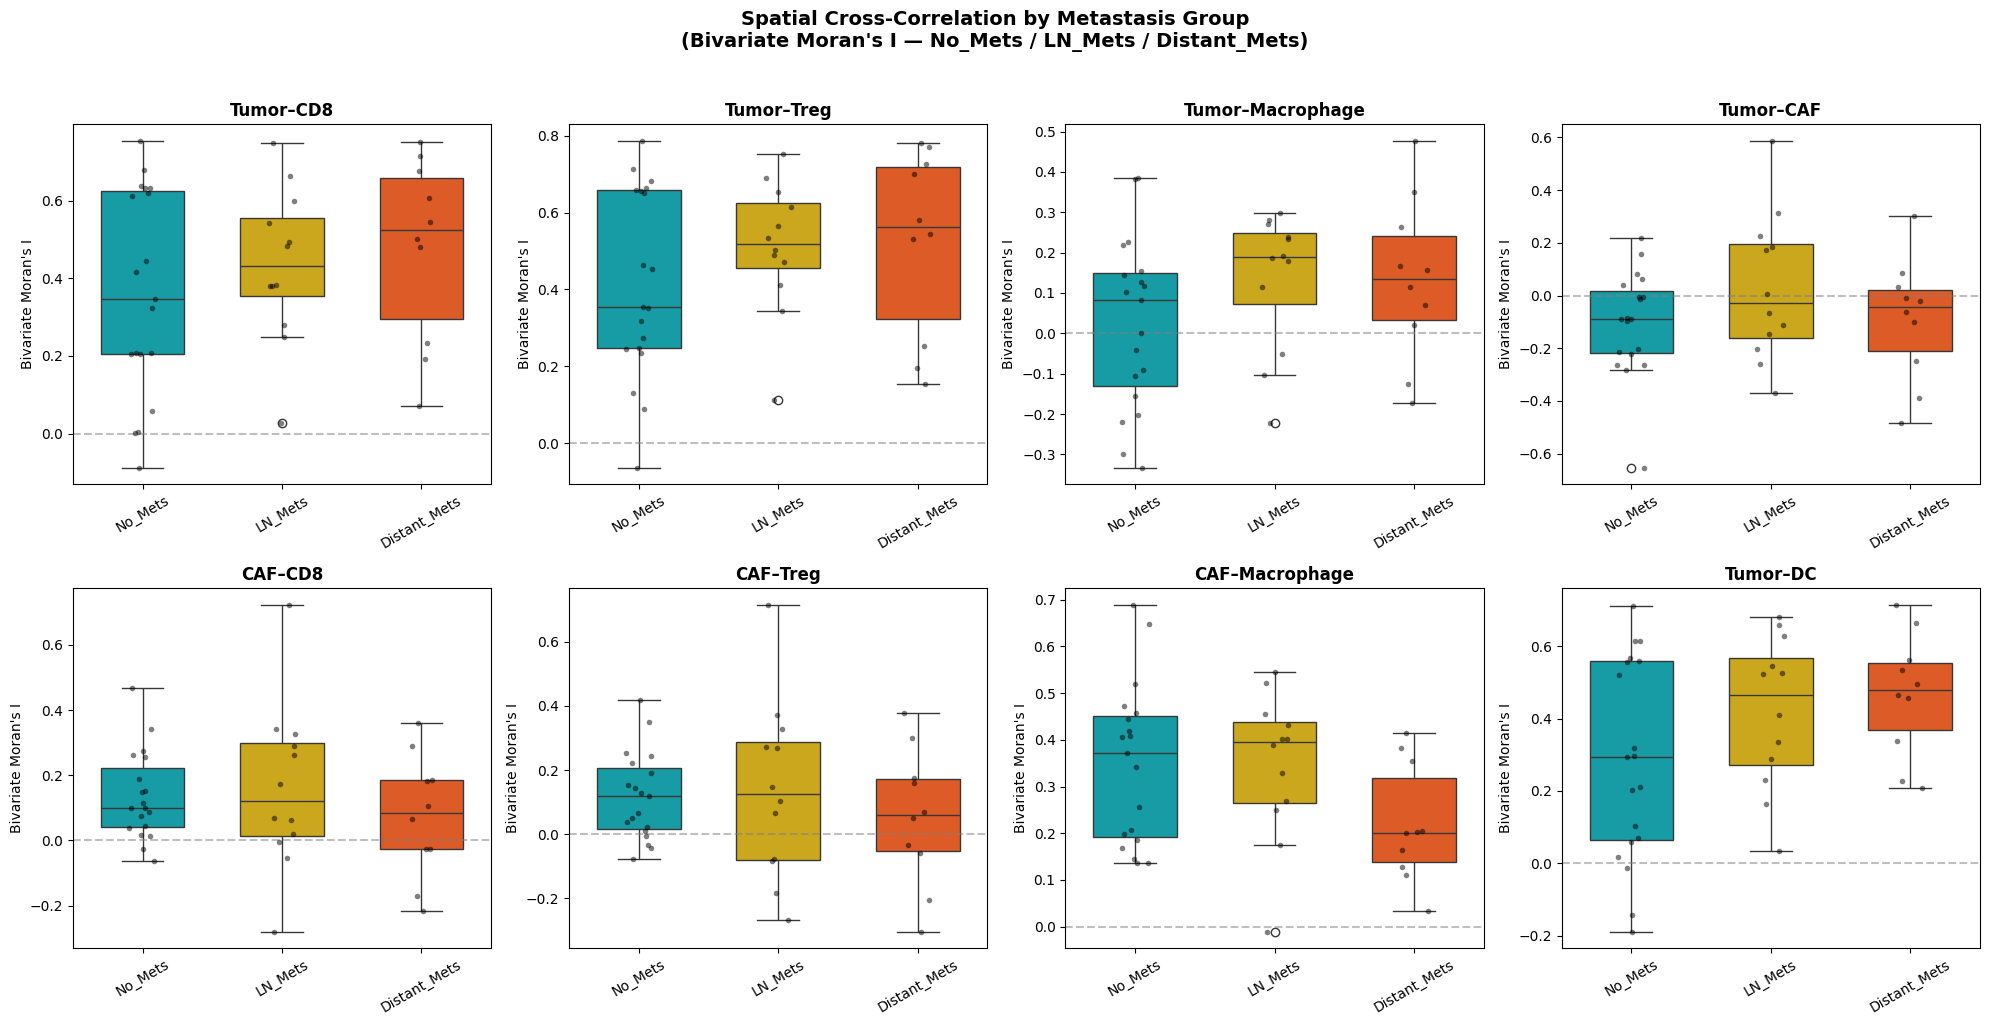

Plot saved to /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation


In [15]:
METS_ORDER_3 = ["No_Mets", "LN_Mets", "Distant_Mets"]
METS_PALETTE_3 = {"No_Mets": "#00AFBB", "LN_Mets": "#E7B800", "Distant_Mets": "#FC4E07"}

pairs_to_plot = results_df["pair"].unique()
n_pairs = len(pairs_to_plot)
n_cols = 4
n_rows = int(np.ceil(n_pairs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), facecolor="white")
axes = axes.flatten() if n_pairs > 1 else [axes]

for idx, pair in enumerate(pairs_to_plot):
    ax = axes[idx]
    sub = results_df[results_df["pair"] == pair]
    
    sns.boxplot(data=sub, x="mets_group", y="morans_I", order=METS_ORDER_3,
                palette=METS_PALETTE_3, ax=ax, width=0.6)
    sns.stripplot(data=sub, x="mets_group", y="morans_I", order=METS_ORDER_3,
                  color="black", alpha=0.5, size=4, ax=ax)
    
    ax.set_title(pair, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Bivariate Moran's I")
    ax.axhline(y=0, color="grey", linestyle="--", alpha=0.5)
    ax.tick_params(axis="x", rotation=30)

for idx in range(len(pairs_to_plot), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Spatial Cross-Correlation by Metastasis Group\n"
             "(Bivariate Moran's I \u2014 No_Mets / LN_Mets / Distant_Mets)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "morans_i_boxplots_3group.png"), dpi=200, bbox_inches="tight")
plt.show()
print(f"Plot saved to {OUTPUT_DIR}")

## Boxplots: Two-Group Stratification (Table 1 design)

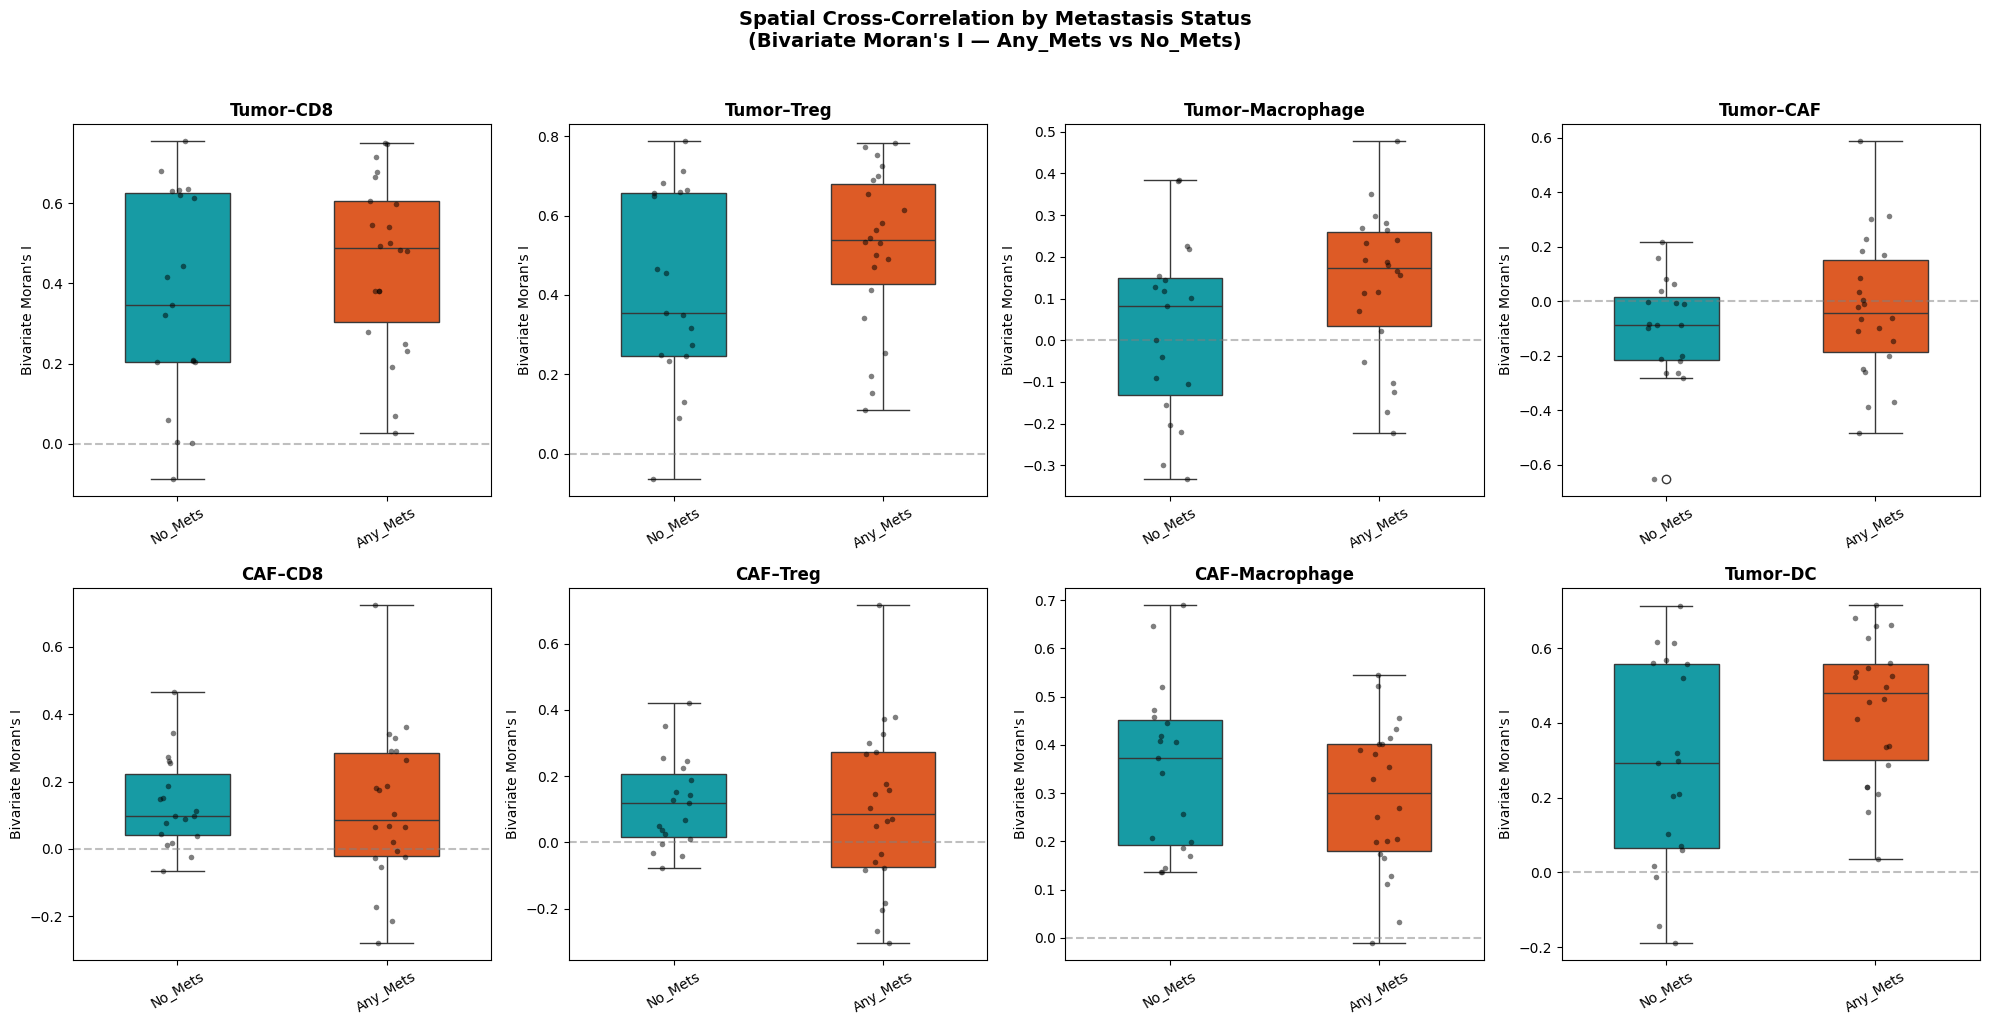

Plot saved to /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation


In [16]:
METS_ORDER_2 = ["No_Mets", "Any_Mets"]
METS_PALETTE_2 = {"No_Mets": "#00AFBB", "Any_Mets": "#FC4E07"}

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), facecolor="white")
axes = axes.flatten() if n_pairs > 1 else [axes]

for idx, pair in enumerate(pairs_to_plot):
    ax = axes[idx]
    sub = results_df[results_df["pair"] == pair]
    
    sns.boxplot(data=sub, x="mets_binary", y="morans_I", order=METS_ORDER_2,
                palette=METS_PALETTE_2, ax=ax, width=0.5)
    sns.stripplot(data=sub, x="mets_binary", y="morans_I", order=METS_ORDER_2,
                  color="black", alpha=0.5, size=4, ax=ax)
    
    ax.set_title(pair, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Bivariate Moran's I")
    ax.axhline(y=0, color="grey", linestyle="--", alpha=0.5)
    ax.tick_params(axis="x", rotation=30)

for idx in range(len(pairs_to_plot), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Spatial Cross-Correlation by Metastasis Status\n"
             "(Bivariate Moran's I \u2014 Any_Mets vs No_Mets)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "morans_i_boxplots_2group.png"), dpi=200, bbox_inches="tight")
plt.show()
print(f"Plot saved to {OUTPUT_DIR}")

## Heatmaps: Mean Moran's I by Pair and Group

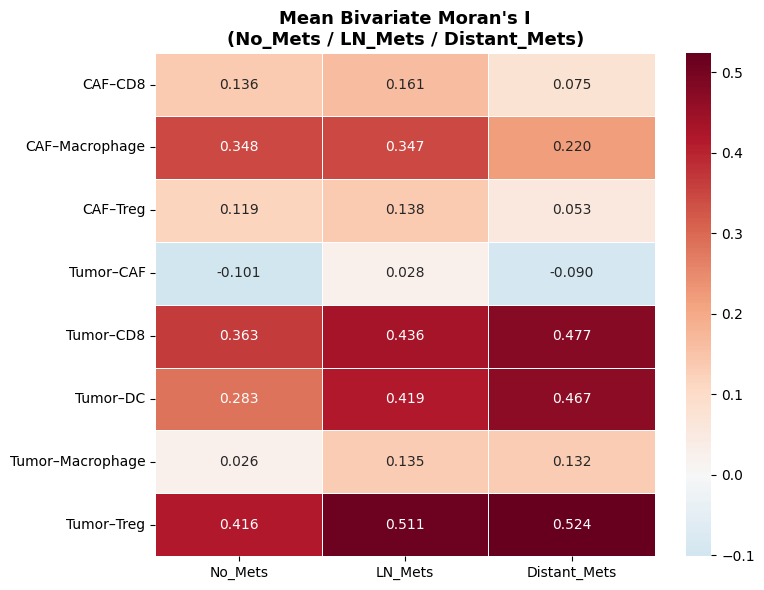

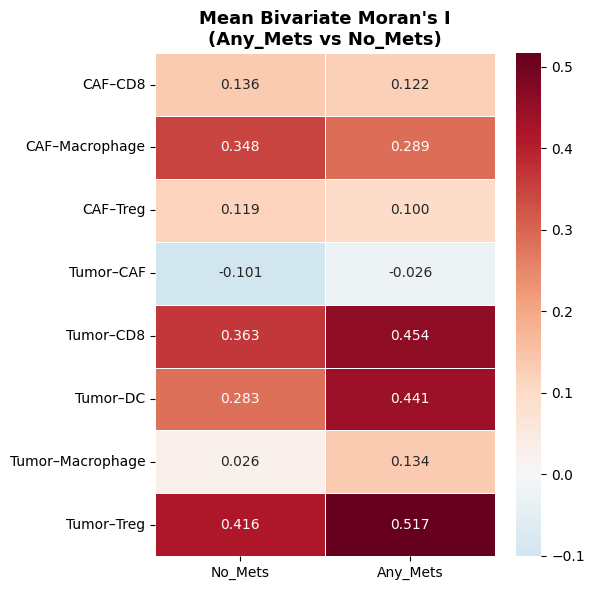


All results saved to /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation
Done!


In [17]:
# Three-group heatmap
pivot_3g = results_df.pivot_table(index="pair", columns="mets_group", values="morans_I", aggfunc="mean")
pivot_3g = pivot_3g.reindex(columns=METS_ORDER_3)

fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
sns.heatmap(pivot_3g, annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_title("Mean Bivariate Moran's I\n"
             "(No_Mets / LN_Mets / Distant_Mets)",
             fontsize=13, fontweight="bold")
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "morans_i_heatmap_3group.png"), dpi=200, bbox_inches="tight")
plt.show()

# Two-group heatmap
pivot_2g = results_df.pivot_table(index="pair", columns="mets_binary", values="morans_I", aggfunc="mean")
pivot_2g = pivot_2g.reindex(columns=METS_ORDER_2)

fig, ax = plt.subplots(figsize=(6, 6), facecolor="white")
sns.heatmap(pivot_2g, annot=True, fmt=".3f", cmap="RdBu_r", center=0, ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_title("Mean Bivariate Moran's I\n"
             "(Any_Mets vs No_Mets)",
             fontsize=13, fontweight="bold")
ax.set_ylabel("")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "morans_i_heatmap_2group.png"), dpi=200, bbox_inches="tight")
plt.show()

print(f"\nAll results saved to {OUTPUT_DIR}")
print("Done!")